In [1]:
# Import the required libraries
import numpy as np
import scipy as sp
import scipy.linalg as linalg
import matplotlib.pyplot as plt

from src import rk4, solve_ode

## **Ejercicio 2)** Modelo de Izhikevich

In [2]:
def izhikevich_model(x, t, p):
    """
    Derivative function of the Izhikevich model:
        v'(t) = g_2 v^2(t) + g_1 v(t) + g_0 - u(t) + I(t)
        u'(t) = b (c v(t) - u(t))

    Parameters
    ----------
    x : array_like
        State [v, u].
        - v: membrane potential [mV].
        - u: membrane recovery variable.
    t : float
        Current time.
    p : tuple
        Parameters [I, g, v_minus, v_plus, b, c, delta_u].
        - I: input current I(t), as a callable.
        - g: coefficients [g_0, g_1, g_2] of the quadratic term.
        - v_minus: post-spike reset value of v (unused here).
        - v_plus: spike threshold for v (unused here).
        - b: time scale of the recovery variable u.
        - c: sensitivity of u to subthreshold fluctuations of v.
        - delta_u: post-spike increment of u (unused here).

    Returns
    -------
    dx : ndarray
        Time derivative [v'(t), u'(t)].
    """
    v, u = x
    I, g, v_minus, v_plus, b, c, delta_u = p

    dv = g[2] * v**2 + g[1] * v + g[0] - u + I(t)
    du = b * (c * v - u)

    return np.array([dv, du])


def reset(x, t, p):
    """
    Potential reset mechanism (neuronal firing):
        if v >= v_+ :  v <- v_-,  u <- u + delta_u
    
    Parameters
    ----------
    x : array_like
        State [v, u].
        - v: membrane potential [mV].
        - u: membrane recovery variable.
    t : float
        Current time (unused here).
    p : tuple
        Parameters [I, g, v_minus, v_plus, b, c, delta_u].
        - I: input current I(t), as a callable (unused here).
        - g: coefficients [g_0, g_1, g_2] of the quadratic term (unused here).
        - v_minus: post-spike reset value of v.
        - v_plus: spike threshold for v.
        - b: time scale of the recovery variable u (unused here).
        - c: sensitivity of u to subthreshold fluctuations of v (unused here).
        - delta_u: post-spike increment of u.

    """
    v, u = x
    I, g, v_minus, v_plus, b, c, delta_u = p

    v_new = v
    u_new = u

    if v >= v_plus:
        v_new = v_minus
        u_new = u + delta_u

    return np.array([v_new, u_new])

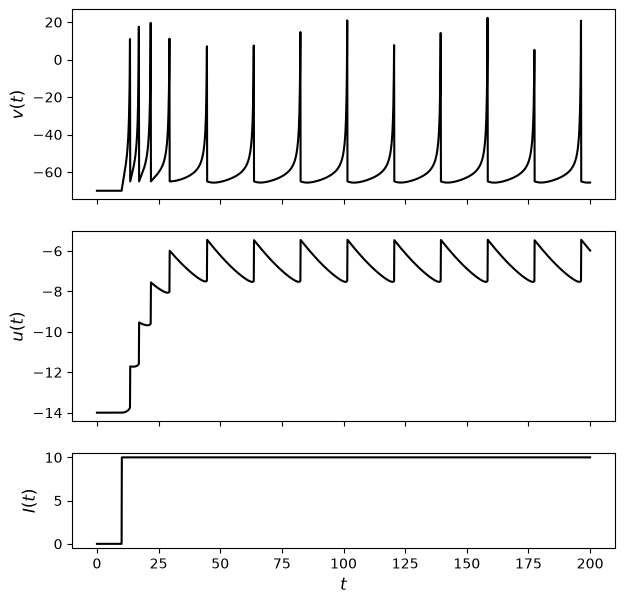

In [3]:
t_i = 0
t_f = 200
h = 0.1

k = int((t_f - t_i) / h)

g = np.array([140, 5, 0.04])
v_minus = -65
v_plus = 30
b = 0.02
c = 0.2
delta_u = 2

def I(t):
    return 0 if t < 10 else 10

p = I, g, v_minus, v_plus, b, c, delta_u

v = -70
u = c * v

xa = np.array([v, u], dtype=np.double)

t_rk4, w_rk4 = solve_ode(rk4, izhikevich_model, xa, t_i, t_f, k, p, c=reset)
I_rk4 = [I(t) for t in t_rk4]

fig, axes = plt.subplots(3, 1, figsize=(7, 7), sharex=True, gridspec_kw={'height_ratios': [2, 2, 1]})

ax = axes[0]

ax.plot(t_rk4, w_rk4[0,:], color="black")
ax.set_ylabel(r"$v(t)$", fontsize=12)

ax = axes[1]

ax.plot(t_rk4, w_rk4[1,:], color="black")
ax.set_ylabel(r"$u(t)$", fontsize=12)

ax = axes[2]

ax.plot(t_rk4, I_rk4, color="black")
ax.set_ylabel(r"$I(t)$", fontsize=12)
ax.set_xlabel(r"$t$", fontsize=12)

plt.show()

## **Ejercicio 3)** Red de neuronas e Izhikevich